In [1]:
!pip install pandasql


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install matplotlib seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

#Modify the path according to where the file is in your filesystem
dataset_path = "data-3.csv" 

df = pd.read_csv(dataset_path)

In [4]:
print("Shape:", df.shape)
print("Data types:")
print(df.dtypes)
print("Missing values:\n", df.isnull().sum())

Shape: (400, 17)
Data types:
dev_budget_usd             int64
marketing_budget_usd       int64
dev_time_months            int64
team_size                  int64
metacritic                 int64
user_score                 int64
genre                        str
platforms_count            int64
is_multiplayer             int64
launch_price_usd           int64
median_playtime_hours    float64
release_month              int64
is_franchise               int64
publisher_size               str
reviews_at_launch          int64
launch_discount          float64
first_year_sales_k       float64
dtype: object
Missing values:
 dev_budget_usd           0
marketing_budget_usd     0
dev_time_months          0
team_size                0
metacritic               0
user_score               0
genre                    0
platforms_count          0
is_multiplayer           0
launch_price_usd         0
median_playtime_hours    0
release_month            0
is_franchise             0
publisher_size           0
r

Insepcting the data: column types, missing values, inconsistency.
Column types we got numerical and categorical.
No missing values.
Inconsisentcies where checked manually for genre and publisher_size.

In [5]:
import pandasql as ps

# function query(sql) will help us write our SQL queries easily
def query(sql):
    return ps.sqldf(sql, globals())

In [6]:
query("""
SELECT launch_discount AS nr
FROM df
WHERE nr> 0.6 OR nr<0;
""")

,nr


In [7]:
query("""
SELECT metacritic AS rating
FROM df
WHERE rating>100 OR rating<0;
""")

,rating


In [8]:
query("""
SELECT user_score AS score
FROM df
WHERE score> 100 OR score<0;
""")

,score


In [9]:
query("""
SELECT release_month AS release
FROM df
WHERE release>11 OR release<0;
""")

,release


These SQL queries check whether the values in columns are within the given bounds or not. If the values were outside of the bound, the query would return those certian rows. Since there are no rows returned, we know that every value is within the required bounds. The bounds were given by the client.

In [10]:
df[["dev_budget_usd", "marketing_budget_usd", "team_size", "dev_time_months", "first_year_sales_k"]].min()


dev_budget_usd          38943.00
marketing_budget_usd     6029.00
team_size                  23.00
dev_time_months             6.00
first_year_sales_k          2.08
dtype: float64

In [11]:
df[["dev_budget_usd", "marketing_budget_usd", "team_size", "dev_time_months", "first_year_sales_k"]].max()


dev_budget_usd          10451118.00
marketing_budget_usd     5174662.00
team_size                    520.00
dev_time_months               60.00
first_year_sales_k          1248.62
dtype: float64

In [12]:
mean = df[["dev_budget_usd", "marketing_budget_usd", "team_size", "dev_time_months", "first_year_sales_k"]].mean().round(2)
print(mean)


dev_budget_usd          1105825.39
marketing_budget_usd     412616.30
team_size                   141.36
dev_time_months              32.62
first_year_sales_k           53.19
dtype: float64


In [13]:
df.sort_values("first_year_sales_k", ascending=False).head(10)


,dev_budget_usd,marketing_budget_usd,dev_time_months,team_size,metacritic,user_score,genre,platforms_count,is_multiplayer,launch_price_usd,median_playtime_hours,release_month,is_franchise,publisher_size,reviews_at_launch,launch_discount,first_year_sales_k
53,6499290,1850323,7,131,69,80,shooter,1,0,30,42.7,11,1,medium,99770,0.35,1248.62
5,4266193,1274032,57,121,77,83,shooter,3,0,60,28.4,10,1,tiny,63634,0.37,834.96
27,3176053,712174,49,79,55,52,shooter,1,1,60,41.7,0,1,large,71617,0.35,809.92
380,2892384,1095886,56,263,66,50,rpg,3,1,40,15.0,10,1,tiny,59255,0.20,800.19
143,3089704,1642574,26,48,83,84,shooter,3,1,70,14.7,2,1,tiny,30427,0.60,529.07
192,4022032,909019,47,80,72,75,strategy,3,1,50,10.9,1,1,large,115747,0.51,484.08
96,1431019,1438757,37,62,84,86,strategy,2,0,60,13.8,8,1,medium,50628,0.39,448.71
241,2124342,645287,16,86,81,79,strategy,1,1,20,32.6,1,1,giant,64433,0.10,427.86
63,2973408,856270,29,102,73,60,rpg,1,1,30,5.0,3,1,giant,27210,0.40,308.46
81,1217107,518641,41,42,66,68,shooter,3,0,70,22.0,10,1,small,42587,0.48,296.08


In [14]:
df.sort_values("first_year_sales_k", ascending=False)[["first_year_sales_k", "dev_budget_usd", "marketing_budget_usd", "team_size", "metacritic"]].head(10)
                                                      

,first_year_sales_k,dev_budget_usd,marketing_budget_usd,team_size,metacritic
53,1248.62,6499290,1850323,131,69
5,834.96,4266193,1274032,121,77
27,809.92,3176053,712174,79,55
380,800.19,2892384,1095886,263,66
143,529.07,3089704,1642574,48,83
192,484.08,4022032,909019,80,72
96,448.71,1431019,1438757,62,84
241,427.86,2124342,645287,86,81
63,308.46,2973408,856270,102,73
81,296.08,1217107,518641,42,66


In [15]:
copy_table = df.copy()
rowsToDrop = []
for i, row in copy_table.iterrows():
    if row["dev_budget_usd"] < 3400000:
        rowsToDrop.append(i)

copy_table.drop(rowsToDrop, inplace=True)
print(copy_table)

     dev_budget_usd  marketing_budget_usd  dev_time_months  team_size  \
3           4610783               3308649               51        155   
5           4266193               1274032               57        121   
39          6854661               3014742                6         56   
53          6499290               1850323                7        131   
67          4850363               2396969               31        201   
106        10451118               2717298                8        126   
111         6127719               3383082               56        118   
136         5492024               2783111               23         76   
139         5463647                667811               16        116   
173         9646383               5174662               10        111   
192         4022032                909019               47         80   
393         4053803               1333248               58        512   

     metacritic  user_score      genre  platforms_

In [16]:
final_copy_table = df.copy()
rowsToDrop = []
for i, row in final_copy_table.iterrows():
    if row["dev_budget_usd"] > 3400000:
        rowsToDrop.append(i)

final_copy_table.drop(rowsToDrop, inplace=True)
print(final_copy_table)


     dev_budget_usd  marketing_budget_usd  dev_time_months  team_size  \
0           1780590                551738               45        112   
1           2361029                943574                7         23   
2           1976102                829247               37        122   
4           1079161                640524               40         49   
6           1373599                941903                8         96   
..              ...                   ...              ...        ...   
395          408942                229168               51        205   
396          357485                 72742               22         43   
397         1440670                494674               23        122   
398          107511                 45800               59        282   
399          223897                 49966               23        186   

     metacritic  user_score      genre  platforms_count  is_multiplayer  \
0            98         100        rpg          

In [27]:
df_corr = final_copy_table.copy()
df_corr=pd.get_dummies(df_corr, dtype=int)
#df_corr = df_corr.astype(int)
#print(df_corr)
df_corr = df_corr.corr('spearman')
df_corr

,dev_budget_usd,marketing_budget_usd,dev_time_months,team_size,metacritic,user_score,platforms_count,is_multiplayer,launch_price_usd,median_playtime_hours,...,genre_adventure,genre_puzzle,genre_rpg,genre_shooter,genre_strategy,publisher_size_giant,publisher_size_large,publisher_size_medium,publisher_size_small,publisher_size_tiny
dev_budget_usd,1.000000,0.853723,-0.007132,0.037999,-0.008846,-0.007551,-0.011815,-0.094225,-0.012318,0.028407,...,-0.020273,0.009840,0.030574,-0.105394,0.083527,0.025464,-0.026591,0.012627,-0.017110,0.005471
marketing_budget_usd,0.853723,1.000000,0.014896,-0.001284,-0.006926,0.000989,-0.023186,-0.041603,0.036865,0.028223,...,-0.019533,0.064486,0.051559,-0.136847,0.041177,-0.039065,-0.037485,0.041464,-0.021588,0.053336
dev_time_months,-0.007132,0.014896,1.000000,0.003281,0.028391,0.068189,0.012189,0.064721,0.006857,-0.031071,...,-0.019123,-0.001025,0.103776,-0.024321,-0.058064,0.028121,0.051350,0.039568,-0.067997,-0.048579
team_size,0.037999,-0.001284,0.003281,1.000000,0.108017,0.104376,-0.029630,0.074052,0.022344,-0.002519,...,0.054487,-0.061999,0.036805,-0.103862,0.073920,-0.036770,-0.014526,-0.089329,0.076309,0.062513
metacritic,-0.008846,-0.006926,0.028391,0.108017,1.000000,0.866407,-0.035964,-0.064229,0.104224,-0.022468,...,0.043992,-0.022440,0.052581,-0.119992,0.046583,0.014783,-0.054253,-0.066311,0.095972,0.009514
user_score,-0.007551,0.000989,0.068189,0.104376,0.866407,1.000000,-0.037503,-0.039983,0.112279,0.007694,...,0.018501,-0.000234,0.028485,-0.092020,0.045433,0.011542,-0.013679,-0.040620,0.093724,-0.049420
platforms_count,-0.011815,-0.023186,0.012189,-0.029630,-0.035964,-0.037503,1.000000,-0.067140,-0.019565,0.060578,...,-0.075484,0.066398,-0.043689,0.071241,-0.019553,-0.026479,0.053409,-0.039987,-0.050308,0.062685
is_multiplayer,-0.094225,-0.041603,0.064721,0.074052,-0.064229,-0.039983,-0.067140,1.000000,0.010989,-0.046653,...,-0.068268,0.029615,-0.004691,0.011315,0.029639,0.062085,0.016160,-0.067082,-0.044261,0.034785
launch_price_usd,-0.012318,0.036865,0.006857,0.022344,0.104224,0.112279,-0.019565,0.010989,1.000000,-0.048412,...,-0.021920,0.073330,-0.014505,-0.019447,-0.016042,-0.121741,-0.104083,0.113452,0.068186,0.037177
median_playtime_hours,0.028407,0.028223,-0.031071,-0.002519,-0.022468,0.007694,0.060578,-0.046653,-0.048412,1.000000,...,0.047235,0.037866,0.011024,-0.046839,-0.045424,-0.042863,0.021730,-0.063135,0.071771,0.012177


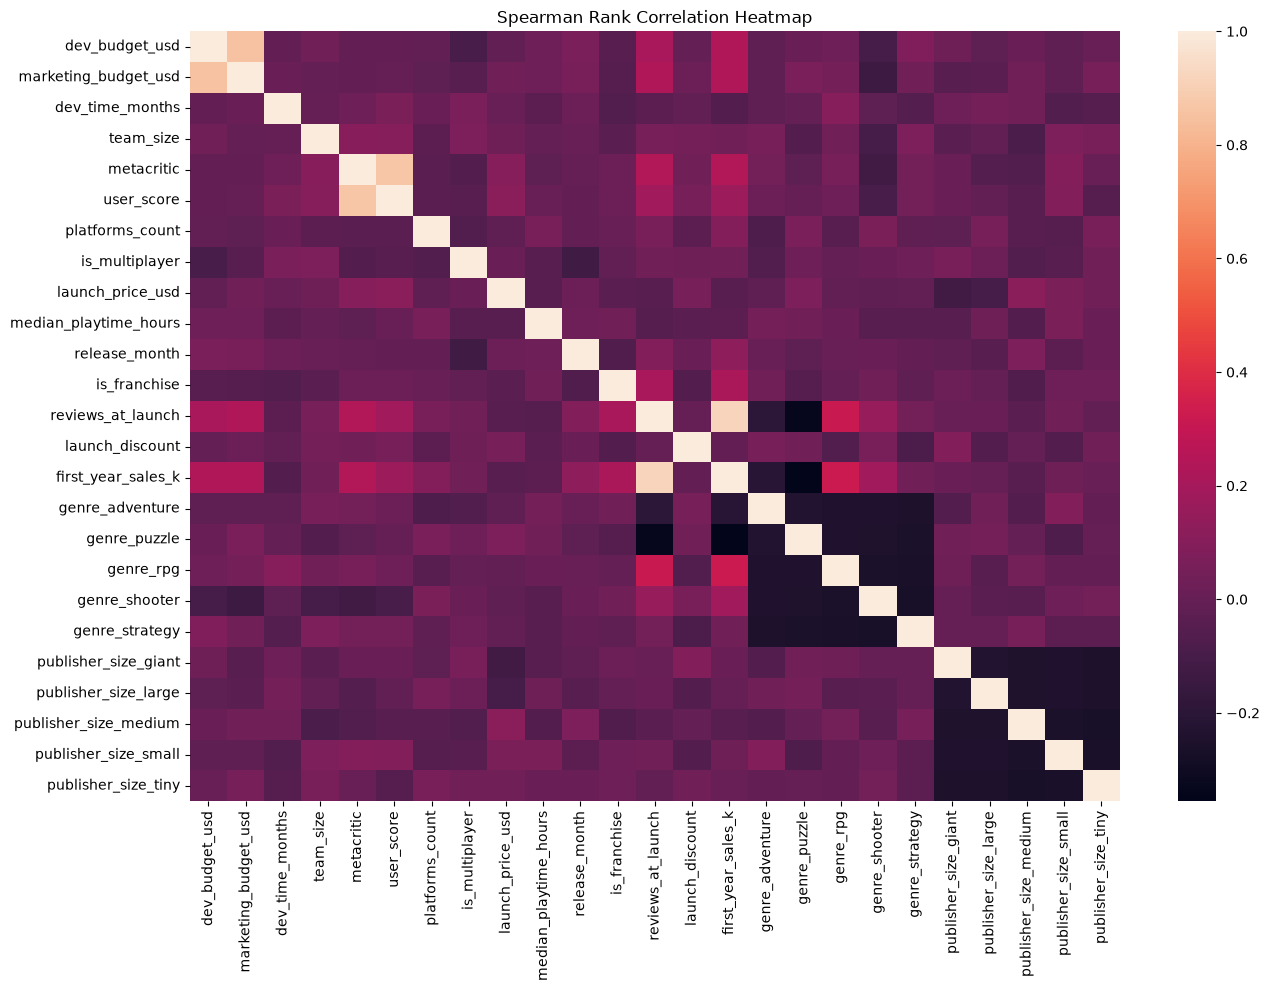

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(15,10))
sns.heatmap(df_corr, ax=ax)
plt.title("Spearman Rank Correlation Heatmap")
plt.show()

In [19]:
query("""
SELECT genre, AVG(first_year_sales_k)
FROM df
GROUP BY genre;
""")

,genre,AVG(first_year_sales_k)
0,adventure,23.837763
1,puzzle,18.160933
2,rpg,74.414250
3,shooter,93.373735
4,strategy,51.166860


In [20]:
query("""
SELECT platforms_count, AVG(first_year_sales_k)
FROM df
GROUP BY platforms_count;
""")

,platforms_count,AVG(first_year_sales_k)
0,1,58.948919
1,2,39.142308
2,3,70.156139
3,4,42.587500


In [32]:
# remove the top few values for demonstration purposes below
df_demonstration = df.copy()
df_demonstration = df_demonstration.drop(df['first_year_sales_k'].nlargest(10).index)

In [33]:
query("""
SELECT is_multiplayer, AVG(first_year_sales_k)
FROM df_demonstration
GROUP BY is_multiplayer;
""")

,is_multiplayer,AVG(first_year_sales_k)
0,0,37.059751
1,1,41.328188


In [55]:
banded = query("""
SELECT
  CASE
    WHEN dev_time_months < 17 THEN 'A (6-16)'
    WHEN dev_time_months < 28 THEN 'B (17-27)'
    WHEN dev_time_months < 38 THEN 'C (28-37)'
    WHEN dev_time_months < 48 THEN 'D (38-47)'
    ELSE 'E (48-60)'
  END AS dev_time_band,
first_year_sales_k
FROM df
""")
banded.groupby("dev_time_band").agg(["count", "mean", "median"]).round(2)

first_year_sales_k              
                           count   mean median
dev_time_band                                 
A (6-16)                      79  70.23  43.14
B (17-27)                     78  40.27  17.23
C (28-37)                     78  42.08  25.81
D (38-47)                     77  47.27  24.91
E (48-60)                     88  64.39  19.53

In [22]:
query("""
SELECT 
  CASE 
    WHEN marketing_budget_usd < 250000 THEN 'A Low (<250000)'
    WHEN marketing_budget_usd BETWEEN 250000 AND 500000 THEN 'B Medium (250000-500000)'
    WHEN marketing_budget_usd BETWEEN 500000 AND 750000 THEN 'High (500000-750000)'
    ELSE 'Very High (>750000)'
  END AS marketing_budget_usd_band,
ROUND(AVG(first_year_sales_k), 2) AS avg_first_year_sales_k
FROM df
GROUP BY marketing_budget_usd_band;
""")

,marketing_budget_usd_band,avg_first_year_sales_k
0,A Low (<250000),30.49
1,B Medium (250000-500000),49.25
2,High (500000-750000),91.73
3,Very High (>750000),111.40


!!!! DROP !!!!

In [23]:
query("""
SELECT 
  CASE 
    WHEN dev_time_months < 20 THEN 'A Low (<20)'
    WHEN dev_time_months BETWEEN 20 AND 35 THEN 'B Medium (20-35)'
    WHEN dev_time_months BETWEEN 35 AND 50 THEN 'High (35-50)'
    ELSE 'Very High (>50)'
  END AS dev_time_months_band,
ROUND(AVG(first_year_sales_k), 2) AS avg_first_year_sales_k
FROM df
GROUP BY dev_time_months_band;
""")

,dev_time_months_band,avg_first_year_sales_k
0,A Low (<20),61.71
1,B Medium (20-35),41.86
2,High (35-50),51.63
3,Very High (>50),64.25


In [ ]:
query("""
SELECT genre, platforms_count, AVG(first_year_sales_k)
FROM df
GROUP BY genre, platforms_count;
""")

,genre,platforms_count,AVG(first_year_sales_k)
0,adventure,1,26.659615
1,adventure,2,22.346957
2,adventure,3,22.190000
3,adventure,4,22.508235
4,puzzle,1,10.794737
5,puzzle,2,15.490714
6,puzzle,3,23.907500
7,puzzle,4,20.351111
8,rpg,1,79.429565
9,rpg,2,46.227692


In [25]:
query("""
SELECT 
  CASE 
    WHEN median_playtime_hours < 10 THEN 'Low (<10)'
    WHEN median_playtime_hours BETWEEN 10 AND 40 THEN 'Medium (10-50)'
    WHEN median_playtime_hours BETWEEN 40 AND 50 THEN 'High (40-50)'
    ELSE 'Very High (>50)'
  END AS median_playtime_hours_band,
ROUND(AVG(first_year_sales_k), 2) AS avg_first_year_sales_k
FROM df
GROUP BY median_playtime_hours_band
ORDER BY avg_first_year_sales_k DESC;
""")

,median_playtime_hours_band,avg_first_year_sales_k
0,High (40-50),171.13
1,Medium (10-50),50.60
2,Low (<10),44.94
3,Very High (>50),44.12


In [26]:
query("""
SELECT 
  CASE 
    WHEN launch_discount < 0.1 THEN '(0.0-0.1)'
    WHEN launch_discount BETWEEN 0.1 AND 0.2 THEN '(0.1-0.2)'
    WHEN launch_discount BETWEEN 0.2 AND 0.3 THEN '(0.2-0.3)'
    WHEN launch_discount BETWEEN 0.3 AND 0.4 THEN '(0.3-0.4)'
    WHEN launch_discount BETWEEN 0.4 AND 0.5 THEN '(0.4-0.5)'
    ELSE '(0.5-0.6)'
  END AS launch_discount_band,
ROUND(AVG(first_year_sales_k), 2) AS avg_first_year_sales_k
FROM df
GROUP BY launch_discount_band
""")

,launch_discount_band,avg_first_year_sales_k
0,(0.0-0.1),45.87
1,(0.1-0.2),50.78
2,(0.2-0.3),41.95
3,(0.3-0.4),87.45
4,(0.4-0.5),33.99
5,(0.5-0.6),59.30
